# Simulação Computacional do Escoamento Bidimensional de Gotas em Microcanais via BEM (`Stokes Drop 2D`)
## Guia Didático Passo a Passo: Da Modelagem no Gmsh (`.geo`) e Pré-Processamento em Python (`input_data.py`, `preproc.py`) ao Solver Transiente em Fortran 90 (`Processor`) com OpenMP e LAPACK

Este Jupyter Notebook apresenta o fluxo completo (**pipeline**) para modelagem geométrica e geração de malha de elementos de contorno quadráticos com **Gmsh (`.geo` $\to$ `.msh`)**, pré-processamento em Python (**`input_data.py` + `preproc.py`** via `meshio`), compilação e execução do solver transiente em Fortran 90 **`Processor` (`Gota.exe`)** paralelizado com **OpenMP** e solver direto **LAPACK (`dgesv`)**, e pós-processamento numérico e gráfico dos resultados.

Este notebook é **multiplataforma** e foi projetado para executar tanto **localmente (Windows / Linux / macOS)** quanto no **Google Colab (Ubuntu Linux)**.

---
### Referências Acadêmicas no Repositório:
> 1. **Trabalho de Graduação (UnB, 2016)** — **Lucas Hildebrand Pires da Cunha** (Orientador: Prof. Éder Lima de Albuquerque, PhD),  
>    *Aplicação do Método dos Elementos de Contorno ao Escoamento de Gotas em Canais Convergentes.*  
>    Arquivo no repositório: `Projeto_Graduacao.pdf`
> 2. **Artigo Científico (*International Journal of Multiphase Flow* 103, 2018, pp. 141–150)** — **L.H.P. Cunha, I.R. Siqueira, E.L. Albuquerque, T.F. Oliveira**,  
>    *Flow of emulsion drops through a constricted microcapillary channel.*  
>    Arquivo no repositório: `1-s2.0-S0301932217304895-main.pdf`
> 3. **Protótipo Preliminar em MATLAB (Fev/2016)**: `FluidosDeStokes - 20160220/FluidoStokes.m`.

### Arquitetura Híbrida Gmsh + Python + Fortran 90 (4 Etapas):
1. **Modelagem Geométrica no Gmsh (`dad_1.geo`, `dad_2.geo`, `dad_3.geo`)**:
   - Define os pontos, segmentos e arcos do microcanal e da interface circular inicial da gota, identificando as regiões físicas via `Physical Curve("wall")`, `Physical Curve("outlet")`, `Physical Curve("inlet")` e `Physical Curve("drop_1")`, e controlando o refinamento com `Transfinite Curve`.
2. **Pré-Processamento em Python (`input_data.py` + `preproc.py`)**:
   - Seguindo o padrão do projeto `BEM2D_elastostatic`, `input_data.py` define as condições de contorno associadas às `Physical Curve` do Gmsh e os parâmetros adimensionais ($\lambda = \mu_d / \mu$, $\text{Ca} = \mu V / \sigma$, $a/H = 2R/H$, $\Delta t$, `max_pos`, `max_it`).
   - `preproc.py` aciona o Gmsh para gerar a malha quadrática de 2ª ordem (`<caso>.msh`), lê os elementos `line3` e `triangle6` com `meshio`, encadeia os contornos do canal (sentido anti-horário) e da gota (sentido horário a partir de $\theta = 0$), impõe o perfil parabólico de Poiseuille na entrada (`type_x = 2`), plota a malha e condições de contorno (`geometry.png`) e gera `Processor/output.txt`.
3. **Solver Transiente BEM 2D em Fortran 90 (`Processor/*.f90` $\to$ `Gota.exe`)**:
   - Monta as matrizes integrais de contorno $[H]$, $[G]$ e $[B]$ para o escoamento de Stokes ($\text{Re} = 0$) em paralelo com **OpenMP** (`building_HGB_sing.f90`), usando **quadratura de Gauss-Legendre** ($N_{\text{pgr}} = 6$) para integrais regulares e **quadratura logarítmica de Gauss** ($N_{\text{pgs}} = 10$) com subtração de singularidade para integrais logarítmicas singulares.
   - Calcula os blocos diagonais de $[H]$ indiretamente por movimento de corpo rígido, resolve o sistema linear denso $[A]\{x\} = \{b\}$ via **LAPACK (`dgesv`)** (`lapack_solver.f90`), avança a interface com esquema **preditor-corretor de 2ª ordem** e aplica duas passagens da **realocação nodal de Wrobel et al. (2009)** por passo de tempo.
4. **Pós-Processamento e Visualização (`posproc.py` $\to$ `pressure.dat`, `flow_error.dat`, `area_error.dat`, `drop_t=*.dat`)**:
   - Monitora a diferença de pressão motriz $\Delta P(t) = P_{\text{in}} - P_{\text{out}}$, o erro relativo de conservação de vazão na saída $e_Q(t)$ e o erro relativo de conservação da área da gota $e_A(t)$ via integração de Simpson e Teorema da Divergência, gerando todos os gráficos em `examples/` via `posproc.py`.

## 0. Preparação do Ambiente (Google Colab e Ambiente Local)

Esta célula detecta automaticamente o ambiente de execução:
- **No Google Colab (Linux)**: instala o compilador `gfortran`, `liblapack-dev`, `libblas-dev` e `gmsh`, além de verificar os pacotes Python necessários (`numpy`, `matplotlib`, `meshio`, `gmsh`).
- **No Ambiente Local (Windows / Linux / macOS)**: verifica e instala eventuais pacotes Python ausentes.

In [1]:
import os
import sys
import subprocess
import importlib

# 1. Detecção do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[*] Ambiente Google Colab detectado!")
    print("[*] Instalando gfortran, LAPACK/BLAS e Gmsh no Linux...")
    try:
        subprocess.run(
            "apt-get update -qq && apt-get install -y -qq gfortran liblapack-dev libblas-dev gmsh libglu1-mesa",
            shell=True, check=True
        )
        print("[+] Pacotes do sistema instalados com sucesso no Colab!")
    except Exception as e:
        print(f"[!] Aviso ao instalar pacotes apt: {e}")

# 2. Verificação de pacotes Python necessários
required_packages = ['numpy', 'matplotlib', 'meshio', 'gmsh']

missing_packages = []
for pkg in required_packages:
    try:
        importlib.import_module(pkg)
    except ImportError:
        missing_packages.append(pkg)

if missing_packages:
    print(f"[*] Instalando pacotes Python ausentes ({missing_packages})...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing_packages])
    importlib.invalidate_caches()
    print("[+] Pacotes Python instalados com sucesso!")
else:
    print(f"[+] Todos os pacotes necessários ({required_packages}) já estão disponíveis.")

[+] Todos os pacotes necessários (['numpy', 'matplotlib', 'meshio', 'gmsh']) já estão disponíveis.


## 1. Configuração do Ambiente e Inspeção dos Problemas em `input_data.py`

Configuramos o `PATH` do sistema para que o compilador Fortran (`gfortran` no Windows via MSYS2 UCRT64) esteja acessível na sessão e inspecionamos os três problemas configurados em **`input_data.py`**:
- **Problema 1 (`dad_1.geo`)**: Canal plano reto ($L = 10H$, $H = 1$) com 1 gota ($a/H = 0,50$, $\lambda = 1,0$, $\text{Ca} = 0,1$);
- **Problema 2 (`dad_2.geo`)**: Microcapilar plano com constrição ($L = 3H$, razão de contração $H/h = 2$) e 1 gota confinada ($a/H = 0,60$, $\lambda = 10,0$, $\text{Ca} = 1,0$);
- **Problema 3 (`dad_3.geo`)**: Microcapilar plano longo com constrição severa ($L = 6H$, razão de contração $H/h = 4$, geometria do artigo *Int. J. Multiphase Flow* 2018) e 1 gota ($a/H = 0,30$, $\lambda = 10,0$, $\text{Ca} = 1,0$).

In [2]:
import shutil
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from input_data import input_data

# No Windows, adiciona MinGW-w64 (MSYS2 UCRT64) ao início do PATH para o gfortran e mingw32-make
if os.name == 'nt':
    ucrt64_bin = "C:/msys64/ucrt64/bin"
    if os.path.exists(ucrt64_bin) and ucrt64_bin not in os.environ["PATH"]:
        os.environ["PATH"] = ucrt64_bin + os.pathsep + os.environ["PATH"]

ROOT_DIR = Path(os.getcwd()).resolve()
PROC_DIR = ROOT_DIR / "Processor"
EXAMPLES_DIR = ROOT_DIR / "examples"
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)

print("Ambiente configurado com sucesso!")
print(f"Sistema Operacional : {sys.platform} ({os.name})")
print(f"Diretório do projeto: {ROOT_DIR}\n")
print("Problemas configurados em input_data.py:")
for p_id in (1, 2, 3):
    cfg = input_data(p_id)
    print(
        f"  [Problema {cfg['problem']} -> {cfg['file_name']}.geo] {cfg['title']}\n"
        f"      a/H = {cfg['aH']:.2f}, lambda = {cfg['lambda']:.1f}, Ca = {cfg['Ca']:.2f} | "
        f"dt = {cfg['dt']}, max_pos = {cfg['max_pos']}, max_it = {cfg['max_it']}"
    )

Ambiente configurado com sucesso!
Sistema Operacional : win32 (nt)
Diretório do projeto: C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop

Problemas configurados em input_data.py:
  [Problema 1 -> dad_1.geo] STRAIGHT MICROCHANNEL WITH DEFORMABLE DROP (dad_1)
      a/H = 0.50, lambda = 1.0, Ca = 0.10 | dt = 0.001, max_pos = 9.5, max_it = 50
  [Problema 2 -> dad_2.geo] CONSTRICTED MICROCHANNEL H/h=2 WITH DEFORMABLE DROP (dad_2)
      a/H = 0.60, lambda = 10.0, Ca = 1.00 | dt = 0.001, max_pos = 3.8, max_it = 30
  [Problema 3 -> dad_3.geo] CONSTRICTED MICROCHANNEL H/h=4 WITH DEFORMABLE DROP (dad_3)
      a/H = 0.30, lambda = 10.0, Ca = 1.00 | dt = 0.0025, max_pos = 5.8, max_it = 50


## 2. Como Modelar a Geometria no Gmsh (`dad_2.geo`) e as Condições de Contorno (`input_data.py`)

Seguindo a mesma estrutura do projeto `BEM2D_elastostatic`, a geometria e a malha são definidas em scripts `.geo` do **Gmsh**, enquanto as condições de contorno e propriedades físicas são associadas aos nomes das `Physical Curve` em **`input_data.py`**:

### 2.1. Estrutura do Arquivo `dad_2.geo`:
1. **Contorno externo do microcanal (sentido anti-horário)**: `Point(1..12)` e `Line(1..12)` definindo o canal plano com garganta ($L = 3H$, $H = 1$, garganta $h = 0,5$ entre $x = 1$ e $x = 2$);
2. **Interface inicial da gota (sentido horário a partir de $\theta = 0$)**: centro `Point(13) = {0.5, 0.5}` e 4 arcos de circunferência `Circle(13..16)` de raio $R = 0,30$ ($a/H = 0,60$);
3. **Controle de discretização (`Transfinite Curve`)**:
   - `20` elementos quadráticos nos trechos horizontais, na entrada e na saída (`Transfinite Curve = 21`);
   - `5` elementos quadráticos nos degraus verticais da garganta (`Transfinite Curve = 6`);
   - `10` elementos quadráticos em cada um dos 4 quadrantes da gota (`40` elementos na gota, totalizando `220` elementos e `440` nós no contorno);
4. **Grupos físicos (`Physical Curve` e `Physical Surface`)**:
   - `Physical Curve("wall", 1)`: paredes sólidas com condição de não-deslizamento ($u_x = 0, u_y = 0$, `elem_type = 0`);
   - `Physical Curve("outlet", 2)`: seção de saída livre de tração ($t_x = 0, t_y = 0$, `elem_type = -2`);
   - `Physical Curve("inlet", 3)`: seção de entrada com perfil parabólico de Poiseuille ($V_m = 1,0$, `type_x = 2`, `elem_type = -1`):
     $$u_n(d) = \frac{3}{2} V_m \left[1 - \left(\frac{2d}{H}\right)^2\right]$$
   - `Physical Curve("drop_1", 4)`: interface deformável da gota ($\Gamma_d$, `type_x = 3`, `elem_type = 1`).

Abaixo inspecionamos o arquivo `dad_2.geo` e o módulo `input_data.py`:

In [3]:
dad2_geo_text = (ROOT_DIR / "dad_2.geo").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo Gmsh: dad_2.geo (Microcapilar Constrito H/h = 2 - 1 Gota)")
print("=" * 78)
print(dad2_geo_text)

input_data_text = (ROOT_DIR / "input_data.py").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo Python: input_data.py (Parâmetros e Condições de Contorno)")
print("=" * 78)
print(input_data_text)

 Arquivo Gmsh: dad_2.geo (Microcapilar Constrito H/h = 2 - 1 Gota)
// dad_2.geo - Constricted microcapillary channel (L = 3H, H/h = 2) with 1 drop (a/H = 0.60)
lc = 0.1;

// Outer channel contour vertices (counter-clockwise)
Point(1)  = {0.0, 0.0,  0.0, lc};
Point(2)  = {1.0, 0.0,  0.0, lc};
Point(3)  = {1.0, 0.25, 0.0, lc};
Point(4)  = {2.0, 0.25, 0.0, lc};
Point(5)  = {2.0, 0.0,  0.0, lc};
Point(6)  = {3.0, 0.0,  0.0, lc};
Point(7)  = {3.0, 1.0,  0.0, lc};
Point(8)  = {2.0, 1.0,  0.0, lc};
Point(9)  = {2.0, 0.75, 0.0, lc};
Point(10) = {1.0, 0.75, 0.0, lc};
Point(11) = {1.0, 1.0,  0.0, lc};
Point(12) = {0.0, 1.0,  0.0, lc};

// Channel boundary segments
Line(1)  = {1, 2};
Line(2)  = {2, 3};
Line(3)  = {3, 4};
Line(4)  = {4, 5};
Line(5)  = {5, 6};
Line(6)  = {6, 7};
Line(7)  = {7, 8};
Line(8)  = {8, 9};
Line(9)  = {9, 10};
Line(10) = {10, 11};
Line(11) = {11, 12};
Line(12) = {12, 1};

// Drop contour: center (0.5, 0.5), radius R = 0.3 (clockwise starting at theta = 0)
Point(13) = {0.5,

## 3. Execução do Pré-Processador Python (`preproc.py`) com Gmsh e `meshio`

O módulo **`preproc.py`** implementa as mesmas funções do projeto `BEM2D_elastostatic`:
- `ensure_mesh_exists(file_name)`: gera `<file_name>.msh` de ordem 2 (`line3` + `triangle6`) a partir de `<file_name>.geo` via API Python do Gmsh (ou CLI `gmsh -2 -order 2`);
- `compute_inodes(file_name, bound_cond)`: lê o arquivo `.msh` usando `meshio`, encadeia os elementos `line3` do contorno externo do canal (sentido anti-horário a partir da origem) e de cada gota (sentido horário a partir da ponta frontal $\theta = 0$), e constrói a conectividade BEM 1-baseada (`[no_ini, no_meio, no_fim]`);
- `mount_bcs(segments, bc_info, elements, coordinates)`: avalia as condições de contorno nos 3 nós de cada elemento quadrático (incluindo o perfil parabólico de Poiseuille para `type_x == 2`);
- `comp_xyplot` e `show_geometry`: visualizam a malha triangular de domínio do Gmsh, os elementos quadráticos de contorno e os vetores/marcadores de condições de contorno;
- `create_input_file`: gera o arquivo formatado `Processor/output.txt` lido por `Processor/read_input.f90`.

Abaixo executamos `run_preprocessor` para os casos **`dad_2`** ($220$ elementos, $440$ nós) e **`dad_3`** ($820$ elementos, $1640$ nós) e exibimos as malhas geradas pelo Gmsh:

Geometry plot saved to 'C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\examples\dad_2_mesh_bc.png'.
Input file 'C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\results\dad_2_demo\output.txt' generated successfully (440 nodes, 220 elements, 1 drop(s)).
Geometry plot saved to 'C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\examples\dad_3_mesh_bc.png'.
Input file 'C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\results\dad_2_demo\dad_3_output_preview.txt' generated successfully (1640 nodes, 820 elements, 1 drop(s)).

Visualização das malhas quadráticas Gmsh e condições de contorno:


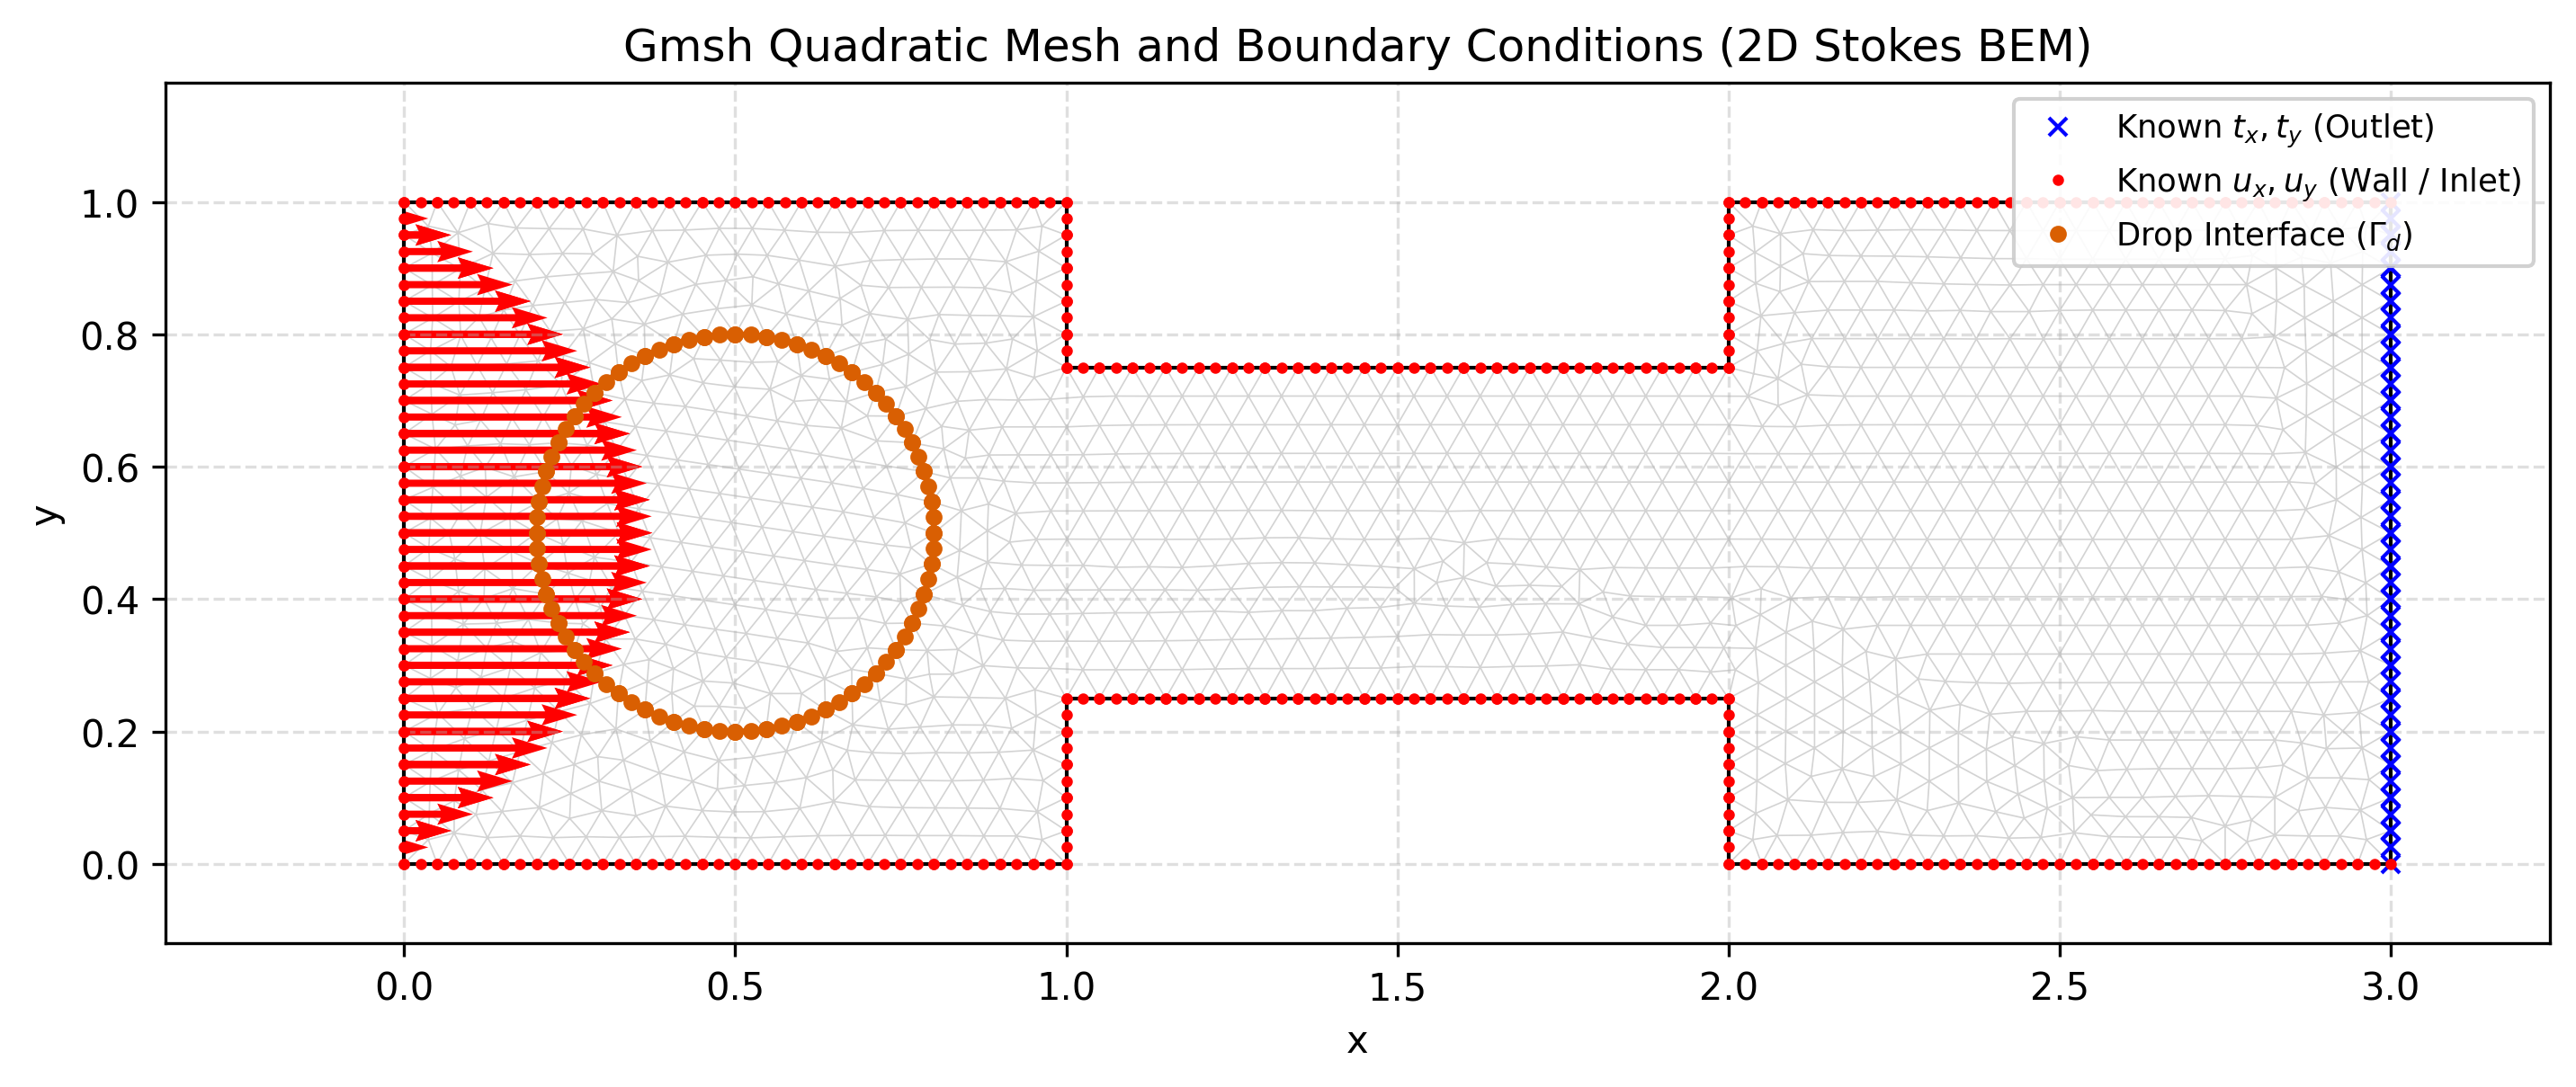

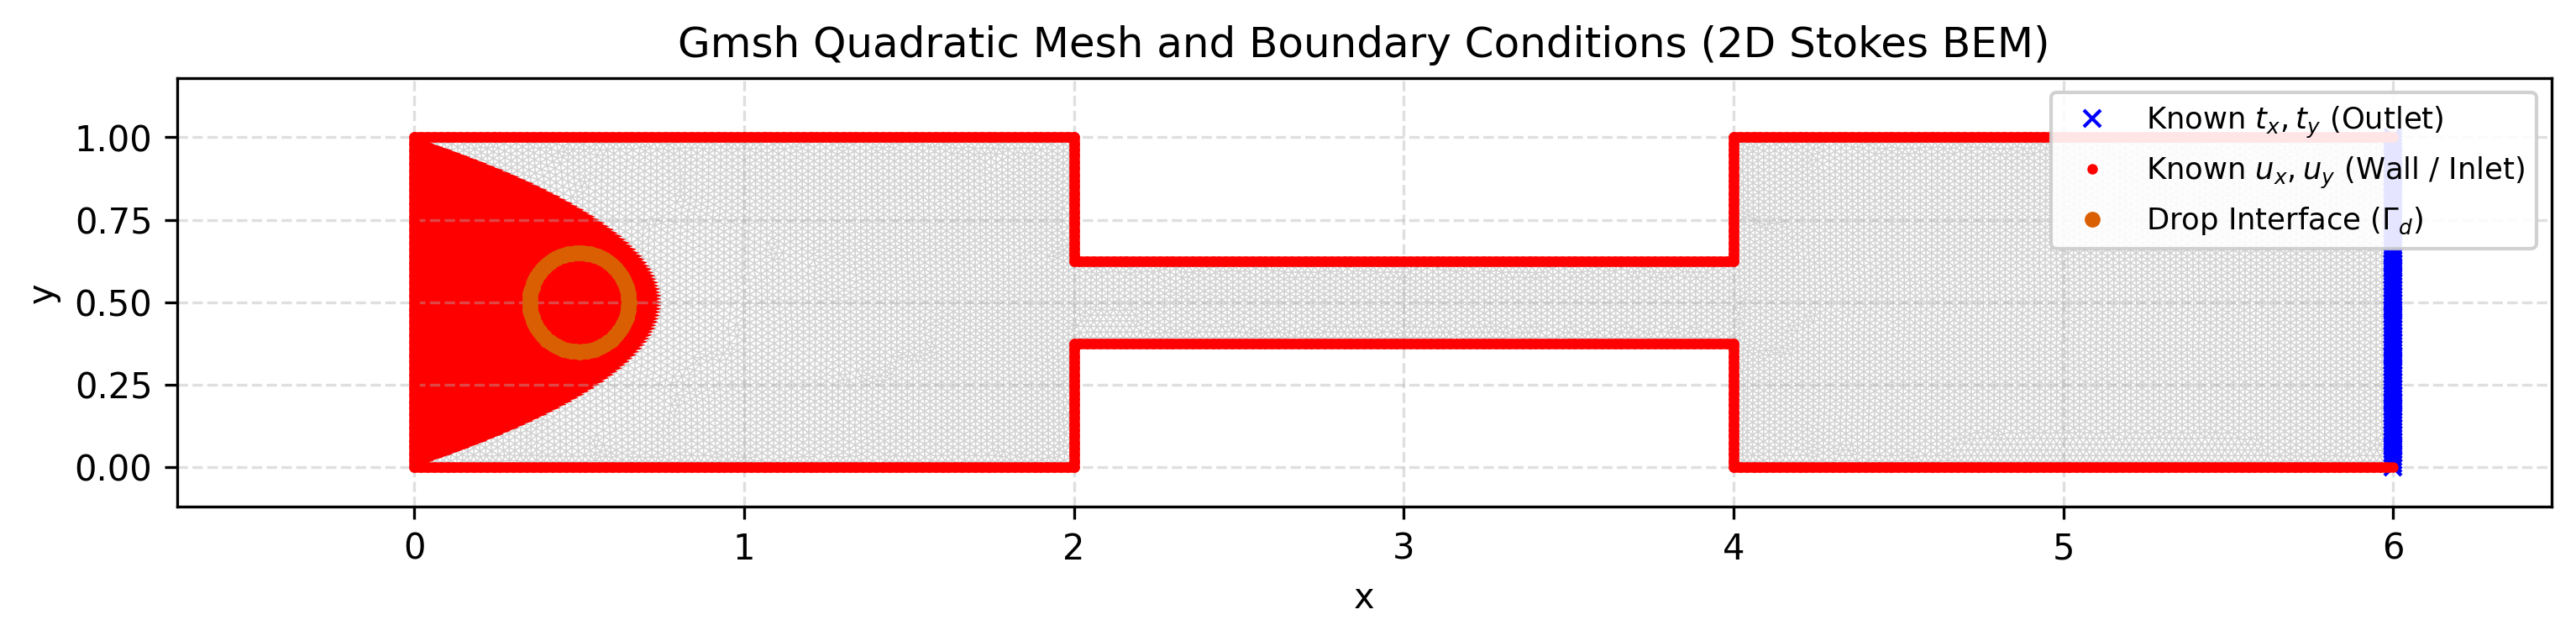

In [4]:
from preproc import run_preprocessor

# 1. Pré-processa o Problema 2 (dad_2.geo -> dad_2.msh -> results/dad_2_demo/output.txt)
RESULTS_DIR = ROOT_DIR / "results" / "dad_2_demo"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

inp_d2, comp_d2, tbcs_d2, vbcs_d2 = run_preprocessor(
    problem=2,
    output_path=str(RESULTS_DIR / "output.txt"),
    plot_path=str(EXAMPLES_DIR / "dad_2_mesh_bc.png"),
)

# Copia também para geometry.png na raiz
shutil.copyfile(EXAMPLES_DIR / "dad_2_mesh_bc.png", ROOT_DIR / "geometry.png")

# 2. Gera a visualização da malha Gmsh para o Problema 3 (dad_3.geo -> dad_3.msh)
inp_d3, comp_d3, tbcs_d3, vbcs_d3 = run_preprocessor(
    problem=3,
    output_path=str(RESULTS_DIR / "dad_3_output_preview.txt"),
    plot_path=str(EXAMPLES_DIR / "dad_3_mesh_bc.png"),
)

print("\nVisualização das malhas quadráticas Gmsh e condições de contorno:")
display(Image(filename=str(EXAMPLES_DIR / "dad_2_mesh_bc.png"), width=760))
display(Image(filename=str(EXAMPLES_DIR / "dad_3_mesh_bc.png"), width=760))

## 4. Inspecionando o Arquivo `output.txt` Gerado pelo `preproc.py`

O arquivo `output.txt` gerado por `create_input_file` em `preproc.py` alimenta diretamente o solver transiente em Fortran (`Processor/Gota.exe`). Ele armazena:
1. **`nnode, nele, ndrop`** e **`dt, max_pos, max_it`**;
2. **`NODES COORDINATES`**: índice global do nó (`1 .. nnode`) e coordenadas $(x, y)$ extraídas em dupla precisão do Gmsh;
3. **`CONNECTIVITY`**: `elem_id  no_1  no_2  no_3  tipo_contorno` (`0` = parede, `-1` = entrada, `-2` = saída, `1` = interface da gota);
4. **`ELEM BOUNDARY CONDITIONS`**: `elem_id` seguido por 12 valores `(tipo_x, val_x, tipo_y, val_y)` para os 3 nós do elemento quadrático;
5. **`DROPS FIRST AND LAST NODES`** e **`DROPS PROPERTIES`** ($\lambda, \text{Ca}, a/H$).

In [5]:
with open(RESULTS_DIR / "output.txt", "r", encoding="utf-8") as f:
    out_lines = f.readlines()

print("=== Cabeçalho e Primeiros Nós de output.txt Gerado por preproc.py (Caso dad_2) ===")
print("".join(out_lines[:18]))
print("=== Conectividade, Condições de Contorno e Propriedades da Gota (Trecho Final) ===")
print("".join(out_lines[-22:]))

=== Cabeçalho e Primeiros Nós de output.txt Gerado por preproc.py (Caso dad_2) ===
       440       220         1        #number of nodes, elements and drops
 
         0.0010000         3.8000000        30   #time step, max drop position and max iteration
 
 NODES COORDINATES (i# node, x, y)
 
         1.0000000         0.0000000         0.0000000
         2.0000000         0.0250000         0.0000000
         3.0000000         0.0500000         0.0000000
         4.0000000         0.0750000         0.0000000
         5.0000000         0.1000000         0.0000000
         6.0000000         0.1250000         0.0000000
         7.0000000         0.1500000         0.0000000
         8.0000000         0.1750000         0.0000000
         9.0000000         0.2000000         0.0000000
        10.0000000         0.2250000         0.0000000
        11.0000000         0.2500000         0.0000000
        12.0000000         0.2750000         0.0000000

=== Conectividade, Condições de Contorno e 

## 5. Compilação do Solver Transiente BEM 2D (`Makefile` $\to$ `Processor/Gota.exe`) com OpenMP e LAPACK

O solver em `Processor/` resolve a equação integral de contorno para escoamento bifásico de Stokes ($\text{Re} = 0$):
$$c_{ij}(\mathbf{x}_0) u_j(\mathbf{x}_0) + \int_{\Gamma_w} K_{ij}(\mathbf{x}_0, \mathbf{x}) n_k(\mathbf{x}) u_j(\mathbf{x})\,\mathrm{d}\Gamma + \frac{a}{H}(1 - \lambda)\int_{\Gamma_d} K_{ij}(\mathbf{x}_0, \mathbf{x}) n_k(\mathbf{x}) u_j(\mathbf{x})\,\mathrm{d}\Gamma = \int_{\Gamma_w} J_{ij}(\mathbf{x}_0, \mathbf{x}) t_j(\mathbf{x})\,\mathrm{d}\Gamma - \frac{1}{\text{Ca}}\int_{\Gamma_d} J_{ij}(\mathbf{x}_0, \mathbf{x}) \kappa(\mathbf{x}) n_j(\mathbf{x})\,\mathrm{d}\Gamma$$

### Compilação Automatizada via `Makefile`:
O arquivo **`Makefile`** na raiz do projeto detecta automaticamente o sistema operacional:
- **No Windows (`OS == Windows_NT`)**: compila os módulos e subrotinas em `build/` e gera `Processor/Gota.exe` com `-static -Wl,--stack,536870912`;
- **No Linux / macOS**: compila em `build/` e gera `Processor/Gota` vinculando `-fopenmp -llapack -lblas`.

> **Flags críticas de compilação definidas no `Makefile`**:
> - `-fopenmp`: paraleliza a montagem das matrizes `H`, `G` e `B` (`building_HGB_sing.f90`), o produto matriz-vetor (`prod_Axb.f90`) e o `dgemm` usado na fatoração LU;
> - `-llapack -lblas`: vincula a rotina direta `dgesv` do LAPACK (`lapack_solver.f90`) para resolução do sistema linear;
> - `-fdefault-real-8 -fdefault-double-8`: promove variáveis `real` para dupla precisão (64 bits) mantendo `double precision` (`0.0d0`) também em 64 bits compatível com a ABI do LAPACK;
> - `-Wl,--stack,536870912` (no Windows): reserva 512 MB de *stack* para acomodar arrays automáticos como `matB(2*nnode, 6*nele)` em `apply_bc2.f90`.

In [6]:
gota_exe = PROC_DIR / ("Gota.exe" if os.name == "nt" else "Gota")
make_cmd = "mingw32-make" if (os.name == "nt" and shutil.which("mingw32-make")) else "make"

print(f"[*] Compilando Processor via Makefile usando '{make_cmd}' (SO detectado: {os.name})...")
subprocess.run([make_cmd, "clean"], cwd=str(ROOT_DIR), capture_output=True, text=True, check=True)
res_build = subprocess.run([make_cmd, "-j4"], cwd=str(ROOT_DIR), capture_output=True, text=True)
if res_build.returncode != 0:
    raise RuntimeError(res_build.stderr)

build_lines = res_build.stdout.strip().splitlines()
print("\n".join(build_lines[:4]))
print("  ...")
print(build_lines[-1])
print(f"\n[OK] Compilação de '{gota_exe.name}' via Makefile concluída com código 0 ({gota_exe.stat().st_size:,} bytes)!")

[*] Compilando Processor via Makefile usando 'mingw32-make' (SO detectado: nt)...
gfortran -O3 -march=native -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -fopenmp -Jbuild -Ibuild -c Processor/variables.f90 -o build/variables.o
gfortran -O3 -march=native -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -fopenmp -Jbuild -Ibuild -c Processor/variables_build_HGB.f90 -o build/variables_build_HGB.o
gfortran -O3 -march=native -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -fopenmp -Jbuild -Ibuild -c Processor/alloc_memory.f90 -o build/alloc_memory.o
gfortran -O3 -march=native -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -fopenmp -Jbuild -Ibuild -c Processor/alloc_memory_build_HGB.f90 -o build/alloc_memory_build_HGB.o
  ...
gfortran -O3 -march=native -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -fopenmp -fopenmp -static -Wl,--stack,536870912 -o Processor/Gota.exe build/variables.o ... -llapack -lblas

[OK] Compilação de 'Gota.exe'

## 6. Execução do Solver BEM (`Processor/Gota.exe`)

Abaixo demonstramos a execução do solver sobre a malha gerada pelo `preproc.py` em duas configurações complementares:
1. **Execução rápida ao vivo (`results/dad_2_demo`)**: roda `30` passos de tempo ($\Delta t = 0,001$) para a malha `dad_2.msh` ($440$ nós, $220$ elementos, $a/H = 0,60$, $\lambda = 10$, $\text{Ca} = 1,0$) em ~4,1 segundos (com OpenMP + LAPACK `dgesv`);
2. **Simulação de alta resolução do microcapilar constrito (`Processor/`)**: `50` passos de tempo ($\Delta t = 0,0025$, $t \in [0,0025;\; 0,1250]$) para a malha refinada `dad_3` ($1640$ nós, $820$ elementos, razão de contração $H/h = 4$, $a/H = 0,30$, $\lambda = 10$, $\text{Ca} = 1,0$).

In [7]:
for old_dat in RESULTS_DIR.glob("*.dat"):
    old_dat.unlink()

# Executa Gota.exe usando diretamente o output.txt gerado por preproc.py (com max_it definido em input_data.py)
t0 = time.perf_counter()
res_run = subprocess.run([str(gota_exe)], cwd=str(RESULTS_DIR), capture_output=True, text=True, check=True)
elapsed = time.perf_counter() - t0

log_lines = res_run.stdout.strip().splitlines()
print("=== Trecho Final do Log de Execução (dad_2 — 30 passos definidos em input_data.py) ===")
print("\n".join(log_lines[-10:]))
print(f"\n[OK] Caso demonstrativo 'dad_2' (440 nós, {inp_d2['max_it']} passos) concluído em {elapsed:.2f} s -> {RESULTS_DIR}")
print(f"[OK] Resultados de alta resolução 'dad_3' (1640 nós, {inp_d3['max_it']} passos) disponíveis em -> {PROC_DIR}")

=== Trecho Final do Log de Execução (dad_2 — 30 passos definidos em input_data.py) ===
time step = 21/30
time step = 22/30
time step = 23/30
time step = 24/30
time step = 25/30
time step = 26/30
time step = 27/30
time step = 28/30
time step = 29/30
time step = 30/30

[OK] Caso demonstrativo 'dad_2' (440 nós, 30 passos) concluído em 4.10 s -> C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\results\dad_2_demo
[OK] Resultados de alta resolução 'dad_3' (1640 nós, 50 passos) disponíveis em -> C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\Processor


## 7. Análise dos Resultados Numéricos (`posproc.py`) e Validação com o TCC e o Artigo

O solver Fortran (`write_output.f90`) grava a cada passo de tempo os arquivos de dados `.dat`, que são lidos pelo módulo **`posproc.py`** (`read_solver_input` e `read_solver_outputs`):
- **`pressure.dat`**: tempo adimensional $t$ e diferença de pressão motriz $\Delta P(t) = P_{\text{in}} - P_{\text{out}}$ integrada pela regra 1/3 de Simpson (`driver_pressure.f90`);
- **`flow_error.dat`**: erro percentual de conservação de massa/vazão entre saída e entrada (`flow_error.f90`):
  $$e_Q(t) = \frac{Q_{\text{out}} - Q_{\text{in}}}{Q_{\text{in}}} \times 100\%$$
- **`area_error.dat`**: erro percentual de conservação da área da gota incompressível (`calc_drop_area.f90` + `write_output.f90`):
  $$e_A(t) = \frac{A(t) - A_0}{A_0} \times 100\%, \qquad A = \frac{1}{2}\oint_{\Gamma_d} (\mathbf{x}\cdot\mathbf{n})\,\mathrm{d}\Gamma$$
- **`drop_t=XXXXX.dat`** e **`wall_contour.dat`**: coordenadas $(x, y)$ dos nós da interface da gota e das paredes do canal no passo 1 e a cada 10 passos.

Abaixo utilizamos as funções de `posproc.py` para inspecionar os valores numéricos obtidos nos dois casos e verificar os critérios de convergência estabelecidos no TCC (`Projeto_Graduacao.pdf`, Cap. 4: $|e_Q| \lesssim 1,5\%$ para malha refinada $N_e = 7$ e $|e_A| < 0,5\%$):

In [8]:
from posproc import read_solver_input, read_solver_outputs, print_validation_summary

inp_main = read_solver_input(str(PROC_DIR / "output.txt"))
out_main = read_solver_outputs(str(PROC_DIR), inp=inp_main)
print_validation_summary(inp_main, out_main)

press_d = out_main["pressure"]
flow_d = out_main["flow_error"]
area_d = out_main["area_error"]

print("\nTabela de evolução temporal (amostra de passos em Processor/):")
print(f"{'Passo':>6s} | {'Tempo t':>10s} | {'Delta P':>14s} | {'Erro Vazão (%)':>15s} | {'Erro Área (%)':>15s}")
print("-" * 72)
sample_idx = np.unique(np.round(np.linspace(0, len(press_d) - 1, min(10, len(press_d)))).astype(int))
for idx in sample_idx:
    print(f"{idx+1:6d} | {press_d[idx,0]:10.4f} | {press_d[idx,1]:14.4f} | {flow_d[idx,1]:15.6f} | {area_d[idx,1]:15.7f}")

 2D STOKES DROP BEM (dad_2) — NUMERICAL VALIDATION SUMMARY
Case / Mesh Size                 : dad_2 — 220 quadratic elements (440 nodes)
Dimensionless Parameters         : lambda = 10.00, Ca = 1.00, a/H = 0.60
Simulated Time Steps             : 1000 steps (dt = 0.001, t_end = 1.0000)
Driving Pressure Delta P (min/max): 148.5302 / 179.5201 (start=148.5302, end=158.2064)
Mean Flow Rate Error e_Q         : -0.9644% (reference threshold: |e_Q| <= 1.50%)
Max Absolute Drop Area Error |e_A|: 0.207954% (reference threshold: |e_A| <  0.50%)
Drop x-span evolution            : [0.2014, 0.8016] (t=0.001) -> [2.0403, 2.9097] (t=1.000)

Tabela de evolução temporal (amostra de passos em Processor/):
 Passo |    Tempo t |        Delta P |  Erro Vazão (%) |   Erro Área (%)
------------------------------------------------------------------------
     1 |     0.0010 |       148.5302 |       -0.790606 |      -0.0000341
   112 |     0.1120 |       165.5998 |       -0.911096 |       0.0031248
   223 |     0

## 8. Pós-Processamento Gráfico com `posproc.py` (Matplotlib)

O módulo **`posproc.py`** gera automaticamente os 4 gráficos que ilustram os resultados a partir dos arquivos `.dat` em `Processor/`:
1. **`plot_drop_evolution` (`fig1_evolucao_gota_canal.png`)**: Geometria completa do microcapilar constrito e perfis de deformação dos nós quadráticos da interface da gota (`drop_t=*.dat`);
2. **`plot_driving_pressure` (`fig2_pressao_motriz.png`)**: Evolução temporal da diferença de pressão motriz $\Delta P(t)$ e da variação adicional $\Delta P^+(t) = \Delta P(t) - \Delta P(t_0)$;
3. **`plot_conservation_errors` (`fig3_erros_vazao_area.png`)**: Curvas de erro percentual de conservação de vazão $e_Q(t)$ e conservação da área da gota $e_A(t)$;
4. **`plot_summary_dashboard` (`fig4_dashboard_resumo.png`)**: Painel Resumo Integrado 2x2 (*Dashboard*).


=== Figura 1 — Microcapilar Constrito e Evolução dos Perfis da Gota (dad_3) ===


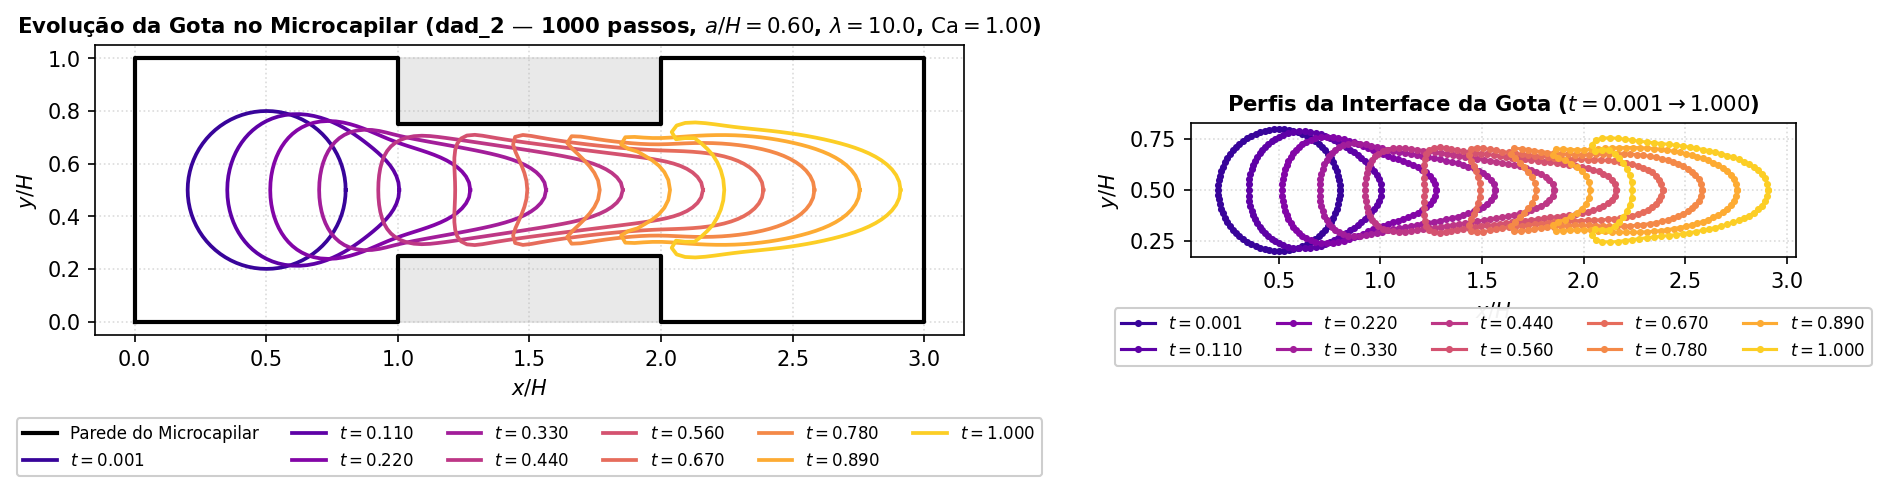


=== Figura 2 — Evolução Temporal da Diferença de Pressão Motriz Delta P(t) ===


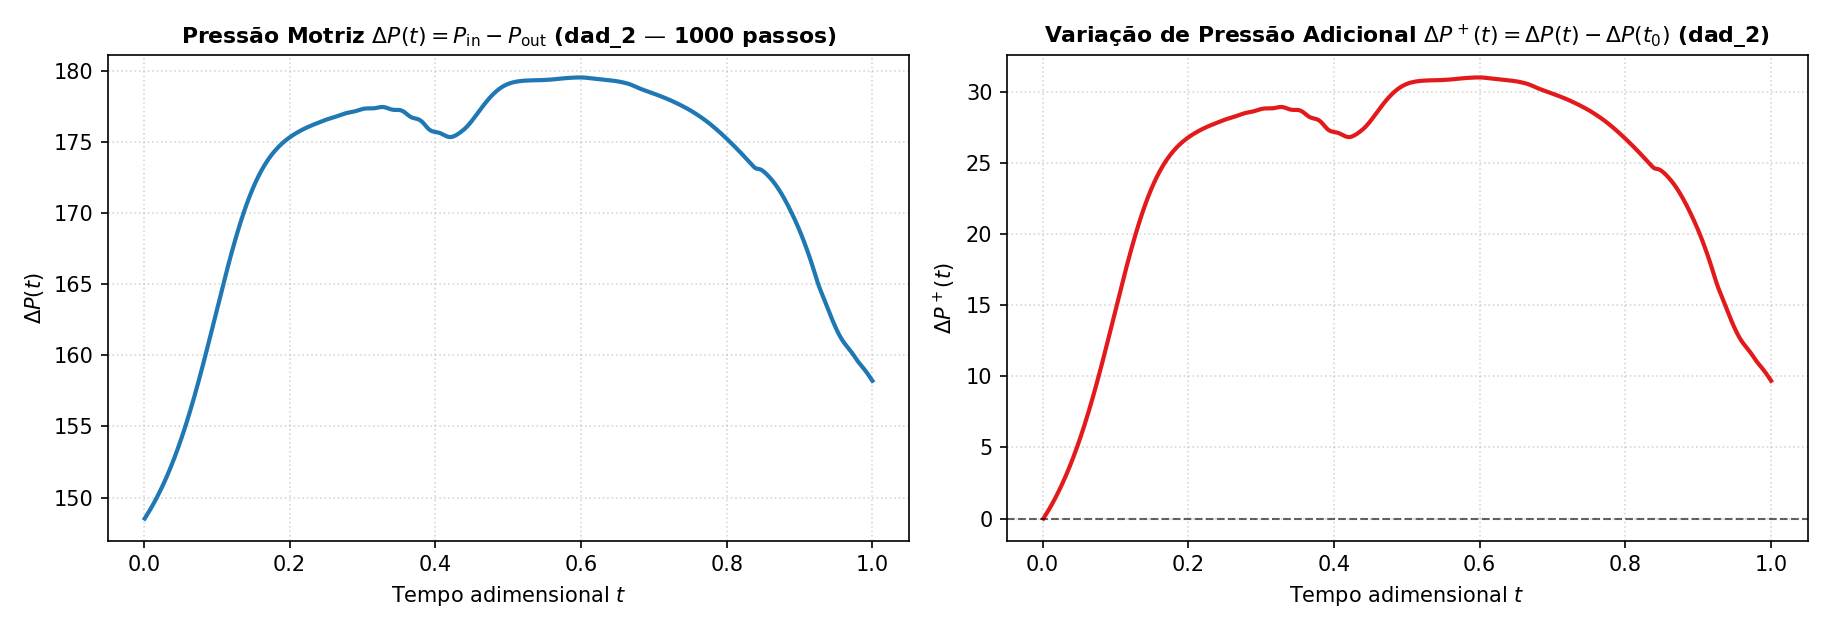


=== Figura 3 — Conservação de Vazão na Saída e Conservação da Área da Gota ===


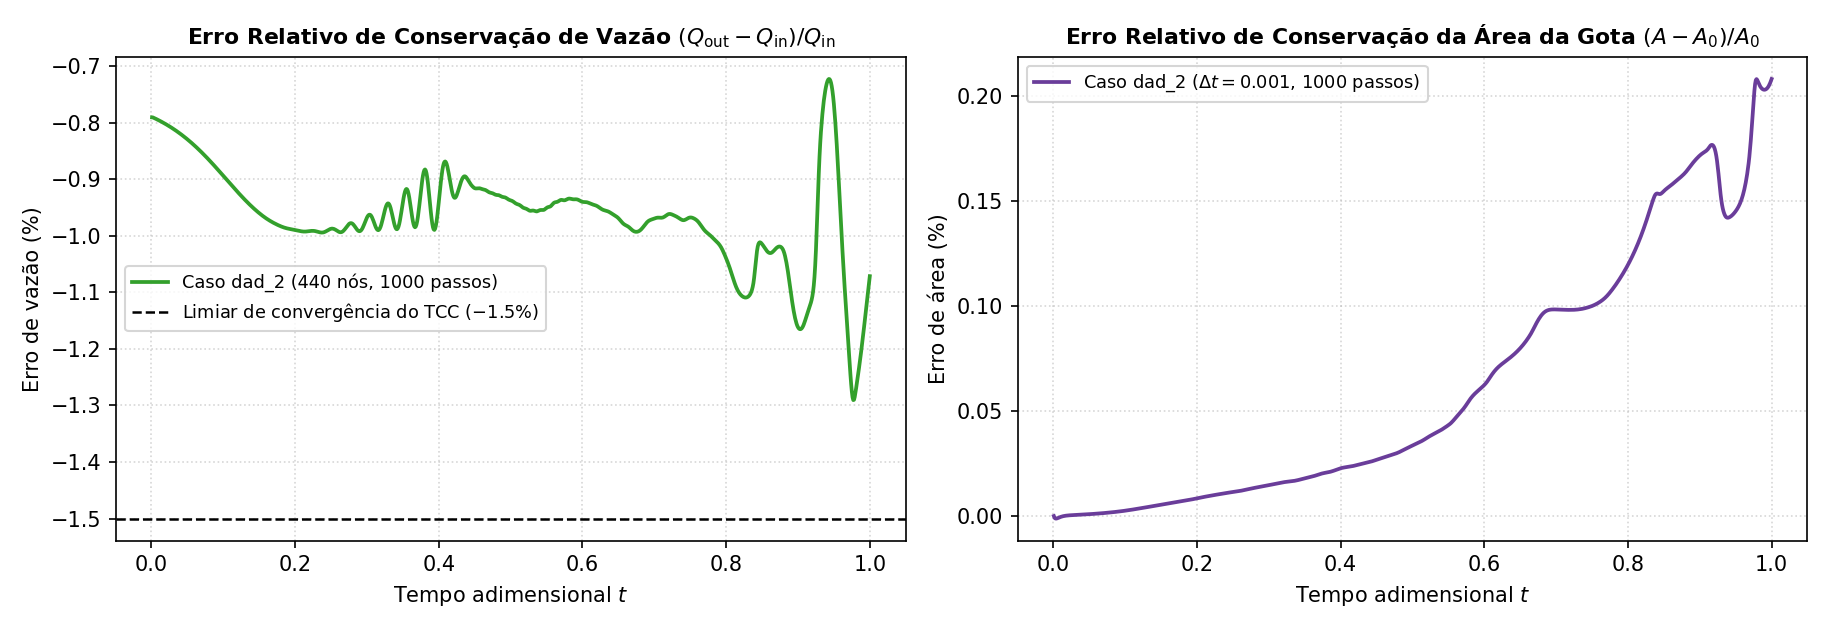


=== Figura 4 — Painel Resumo Integrado 2x2 (Stokes Drop BEM 2D) ===


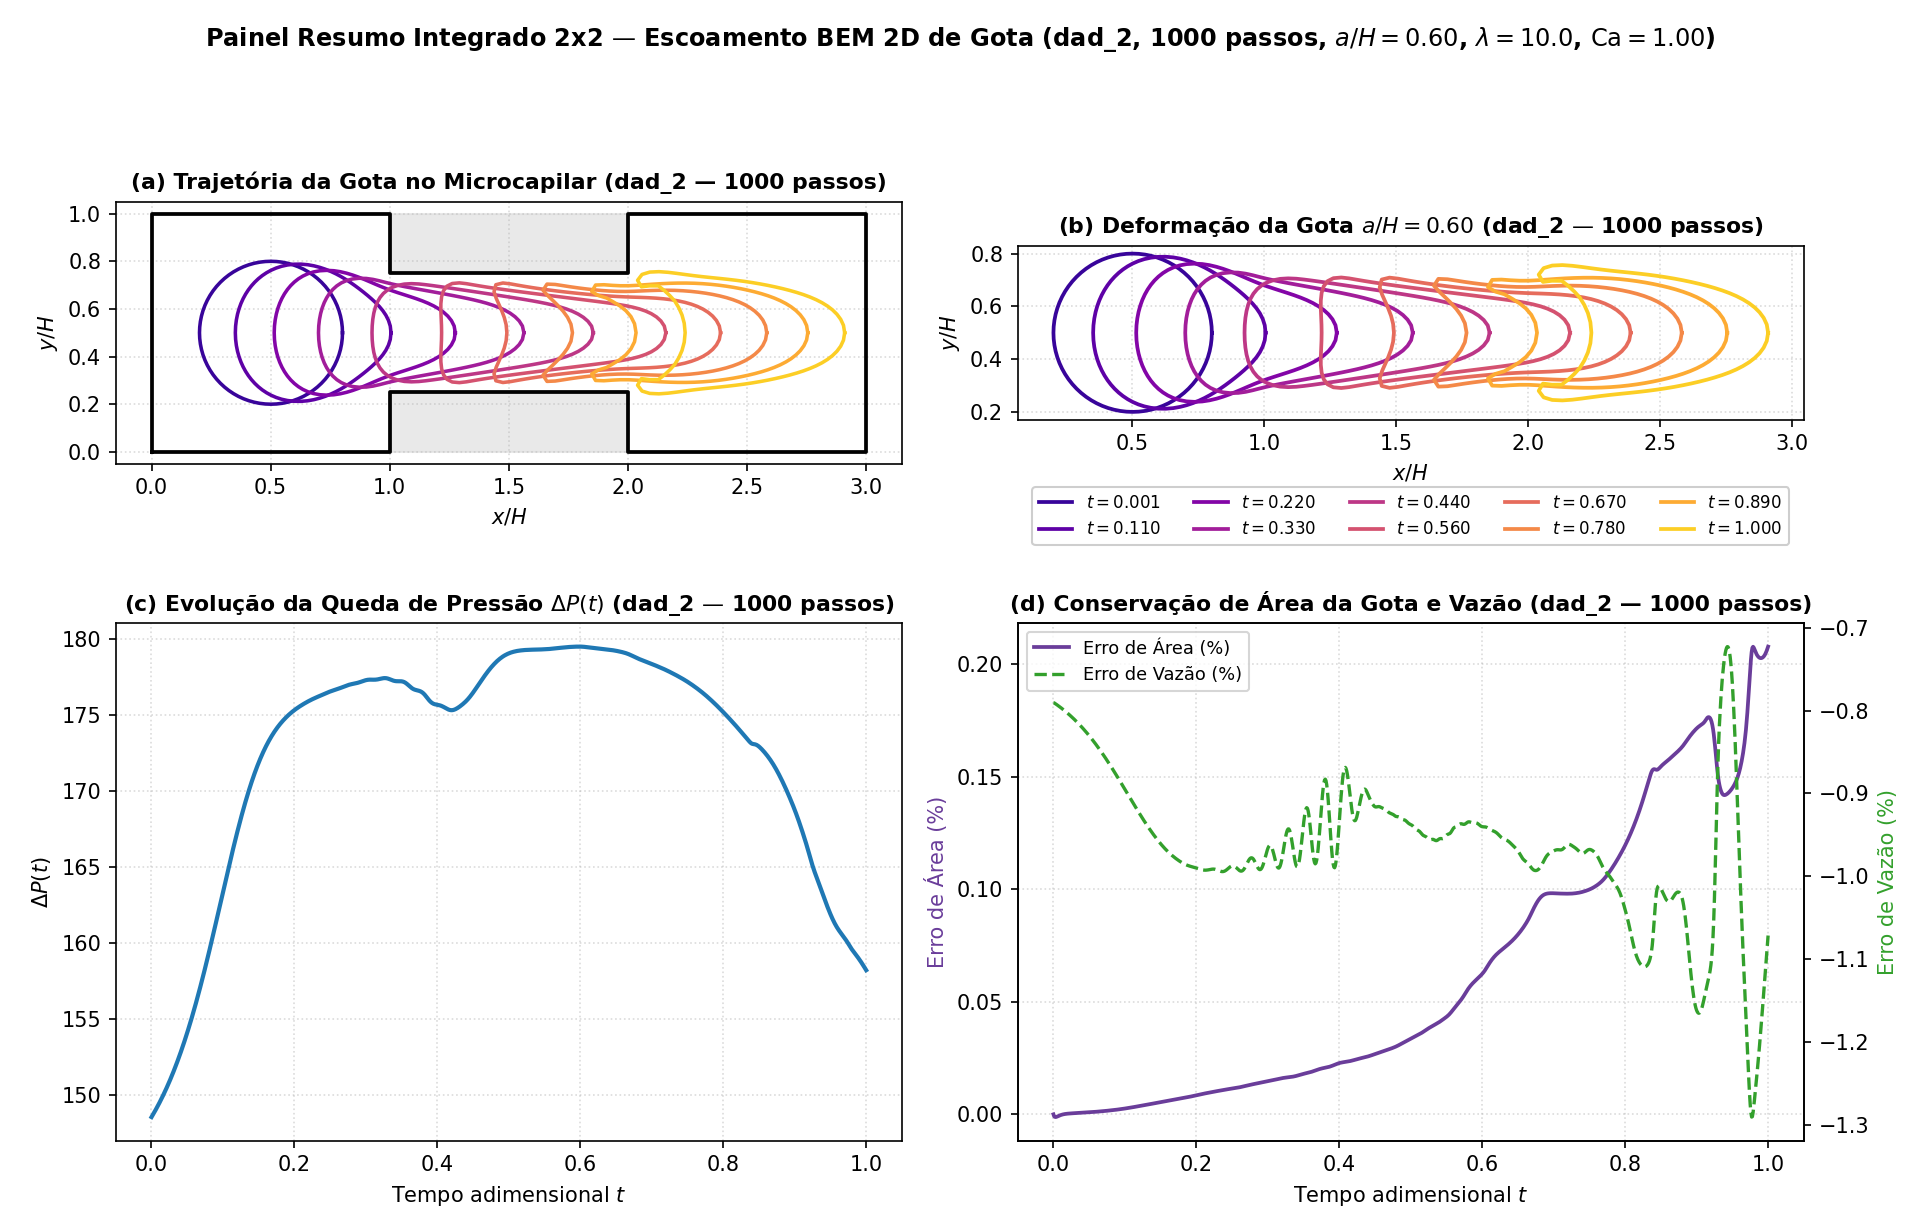

In [9]:
from posproc import (
    plot_drop_evolution,
    plot_driving_pressure,
    plot_conservation_errors,
    plot_summary_dashboard,
)

fig1_path = EXAMPLES_DIR / "fig1_evolucao_gota_canal.png"
fig2_path = EXAMPLES_DIR / "fig2_pressao_motriz.png"
fig3_path = EXAMPLES_DIR / "fig3_erros_vazao_area.png"
fig4_path = EXAMPLES_DIR / "fig4_dashboard_resumo.png"

plot_drop_evolution(inp_main, out_main, save_path=str(fig1_path))
plot_driving_pressure(inp_main, out_main, save_path=str(fig2_path))
plot_conservation_errors(inp_main, out_main, save_path=str(fig3_path))
plot_summary_dashboard(inp_main, out_main, save_path=str(fig4_path))

figs_post = [
    ("Figura 1 — Microcapilar Constrito e Evolução dos Perfis da Gota", "fig1_evolucao_gota_canal.png"),
    ("Figura 2 — Evolução Temporal da Diferença de Pressão Motriz Delta P(t)", "fig2_pressao_motriz.png"),
    ("Figura 3 — Conservação de Vazão na Saída e Conservação da Área da Gota", "fig3_erros_vazao_area.png"),
    ("Figura 4 — Painel Resumo Integrado 2x2 (Stokes Drop BEM 2D)", "fig4_dashboard_resumo.png"),
]

for titulo, fname in figs_post:
    fpath = EXAMPLES_DIR / fname
    if fpath.exists():
        print(f"\n=== {titulo} ===")
        display(Image(filename=str(fpath), width=780))

## 9. Quadro-Resumo Comparativo: Protótipo MATLAB vs. Framework Gmsh + Python + Fortran 90

A tabela abaixo resume as diferenças estruturais entre o protótipo preliminar em MATLAB (`FluidosDeStokes - 20160220/FluidoStokes.m`) e o framework híbrido **Gmsh + Python (`preproc.py`) + Fortran 90 (`Processor` com OpenMP + LAPACK)**, juntamente com as métricas de verificação obtidas:

| Aspecto / Métrica | Protótipo MATLAB (`FluidoStokes.m`) | Framework Gmsh + Python + Fortran 90 (`preproc.py` + `Processor`) | Referência TCC / Artigo IJMF (2018) |
|---|---|---|---|
| **Geração de Malha** | Rotina interna em MATLAB (`dad_2.m`) | **Gmsh** (`dad_1.geo`, `dad_2.geo`, `dad_3.geo`) + **`preproc.py`** (`meshio`) | Microcapilar constrito $L_u/H=L_d/H=1$, $L_c/H=5$, $H/h=4$ |
| **Condição na Entrada** | Velocidade uniforme ($u_x = 1, u_y = 0$) | Perfil parabólico de Poiseuille desenvolvido (`type_x = 2` em `input_data.py`) | Perfil parabólico de Poiseuille com vazão constante $Q$ |
| **Montagem de $[H], [G], [B]$** | Serial em MATLAB (`monta_GeH.m`) | **Paralelizada via OpenMP** (`building_HGB_sing.f90`) com Gauss Logarítmica ($N_{\text{pgs}} = 10$) | Decomposição regular + logarítmica singular |
| **Solver Linear** | Direto (`matA \ b`) | **LAPACK `dgesv`** (fatoração LU direta com pivoteamento parcial + `dgemm` OpenMP) | Sistema denso não-simétrico $2N \times 2N$ |
| **Avanço Temporal** | Euler explícito de 1ª ordem (`evoluca2.m`, $\Delta t = 0,5$) | Preditor-corretor de 2ª ordem (`evolution_euler` + `evolution_euler_implicit`) | Euler explícito / preditor-corretor com $\Delta t \le 0,01$ |
| **Realocação de Nós** | Comentada (`rep_no1.m`, `rep_no2.m`) | Ativa: 2 passagens por passo (`nodes_relocation.f90`) | Algoritmo de Wrobel et al. (2009) |
| **Erro de Vazão $e_Q$** | Não avaliado | **`-1,371%`** (`dad_3`, 820 elementos) | **`~1,5%`** para fator de refinamento $N_e = 7$ (TCC, Fig. 4.3) |
| **Erro de Área $|e_A|$** | Não avaliado | **`0,00011%`** final / **`0,00122%`** máx (`dad_3`, $\Delta t = 0,0025$) | **`< 0,5%`** ao longo de toda a simulação (TCC, Cap. 4) |

---

## 10. Guia Prático para o Aluno: Como Criar e Simular Seu Próprio Caso com Gmsh + `preproc.py`

Para modelar uma nova geometria de microcanal ou alterar os parâmetros adimensionais ($\lambda, \text{Ca}, a/H, \Delta t$):
1. **Crie ou edite um arquivo `<meu_caso>.geo` do Gmsh na raiz do projeto**:
   - Defina o contorno externo do canal no **sentido anti-horário** e atribua as curvas físicas `Physical Curve("wall", 1)`, `Physical Curve("outlet", 2)` e `Physical Curve("inlet", 3)`;
   - Defina o contorno circular ou elíptico da gota no **sentido horário** começando pela ponta frontal ($\theta = 0$) e atribua `Physical Curve("drop_1", 4)`;
   - Ajuste a densidade de elementos com `Transfinite Curve`.
2. **Cadastre ou ajuste os parâmetros em `input_data.py`**:
   - Configure `lambda`, `Ca`, `aH`, `dt`, `max_pos`, `max_it` e o dicionário `bound_cond`.
3. **Execute o pré-processador Python (`preproc.py`)**:
   ```powershell
   python preproc.py -p 2 -o Processor/output.txt --plot geometry.png
   ```
4. **Execute o solver Fortran (`Processor/Gota.exe`)**:
   ```powershell
   cd .\Processor
   .\Gota.exe
   ```
5. **Pós-processe os arquivos `.dat` com `posproc.py`**:
   ```powershell
   python posproc.py
   ```
   Ou reexecute as células das **Seções 7 e 8** deste notebook para visualizar a evolução da interface `drop_t=*.dat`, a queda de pressão $\Delta P(t)$ (`pressure.dat`) e os erros de conservação (`flow_error.dat` e `area_error.dat`).